# 01 · Datos de seguridad vial: dónde muere la gente
**Hackathon de Datos 2026 · ITM · Segundos contra vidas**

Este cuaderno limpia los datos de seguridad vial de Medellín y hace el diagnóstico.
Todos los datos se leen desde las URLs de `src/fuentes.py` (la primera ejecución descarga unos 140 MB).

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import pandas as pd
from IPython.display import Image, display
from src import seguridad as seg, diagnostico as dg
from src.descarga import citar
pd.options.display.float_format = "{:,.2f}".format
print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: C:\Users\Josue Tamayo\source\repos\segundos-contra-vidas


## 1. Datos limpios

In [2]:
inc = seg.incidentes_limpios()
vic = seg.victimas_limpias()
mor = seg.mortalidad_distrito()
inc, vic, mor = dg.datos()

incidentes_limpios: 702540 leídas | eliminadas (sin fecha o sin gravedad): 0 | final: 702540 | sin coordenadas: 44785 | sin dirección: 15365
victimas_limpias: 1048317 leídas | filas vacías eliminadas: 812474 | sin fecha o gravedad eliminadas: 0 | final: 235843 | sin coordenadas: 22960
mortalidad_distrito: 1541 filas leídas | duplicados exactos eliminados: 0 | sin fecha válida eliminados: 0 | final: 1541


Notas de calidad (ver `docs/limpieza_seguridad.md`):
- Solo 235.843 de las 1.048.317 filas de víctimas son reales; el resto está vacío.
- 2025 solo trae enero–agosto y las víctimas llegan a septiembre de 2021: esos años no se comparan como completos.
- La base del ITM no sirve para contar muertos (registra entre el 52 % y el 91 % de los oficiales); por eso las muertes se cuentan con la capa del Distrito y las víctimas de MEData.

In [3]:
resumen = pd.DataFrame({
    "filas": [len(inc), len(vic), len(mor)],
    "desde": [inc.fecha.min().date(), vic.fecha.min().date(), mor.fecha.min().date()],
    "hasta": [inc.fecha.max().date(), vic.fecha.max().date(), mor.fecha.max().date()],
}, index=["Incidentes (ITM)", "Víctimas (MEData)", "Fallecidos (Distrito)"])
resumen

,filas,desde,hasta
Incidentes (ITM),702540,2008-01-01,2025-08-31
Víctimas (MEData),235843,2014-01-01,2021-09-30
Fallecidos (Distrito),1541,2019-01-01,2024-12-31


## 2. Tendencia y validación de la base del ITM

      itm_incidentes_con_muerto  distrito_fallecidos  cobertura_itm
anio                                                               
2019                        148               251.00           0.59
2020                        172               200.00           0.86
2021                        162               253.00           0.64
2022                        226               247.00           0.91
2023                        160               277.00           0.58
2024                        164               313.00           0.52
figura guardada: 01_tendencia_muertos.png


,anio,itm_incidentes_con_muerto,distrito_fallecidos,cobertura_itm
0,2019,148,251.00,0.59
1,2020,172,200.00,0.86
2,2021,162,253.00,0.64
3,2022,226,247.00,0.91
4,2023,160,277.00,0.58
5,2024,164,313.00,0.52


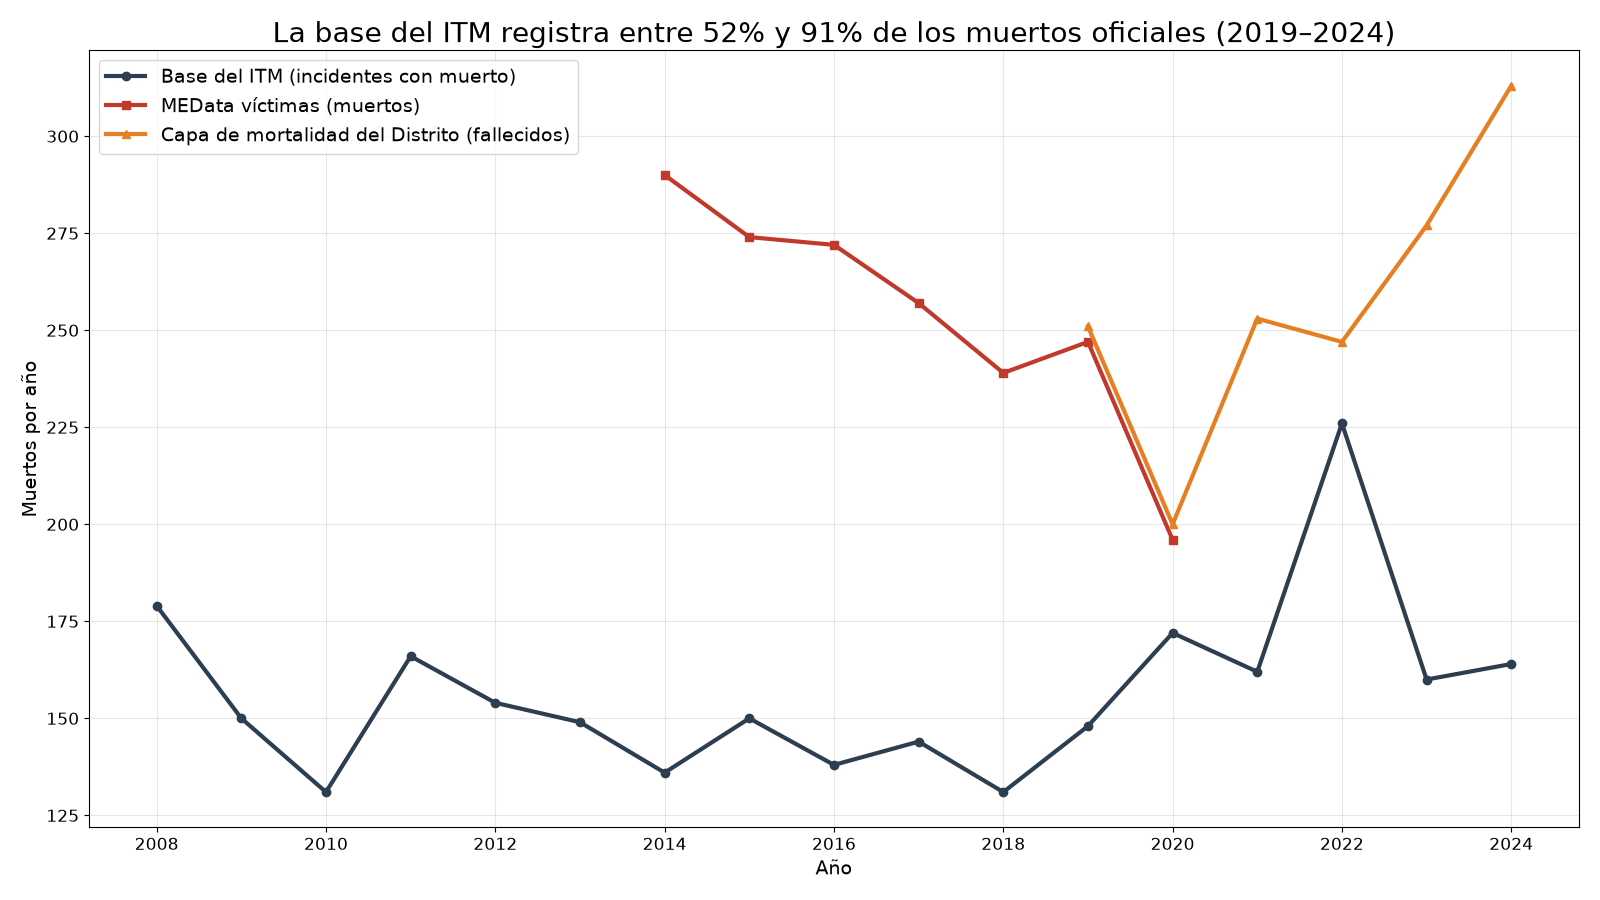

In [4]:
dg.fig_tendencia(inc, vic, mor)
display(pd.read_csv("data/processed/diag_itm_vs_distrito.csv"))
display(Image("figuras/01_tendencia_muertos.png"))

## 3. Hora del día y día de la semana

figura guardada: 02_incidentes_graves_por_hora.png
figura guardada: 03_letalidad_por_hora.png
Letalidad madrugada 1.75% | día 0.66% | razón 2.6x
figura guardada: 04_letalidad_por_dia.png
Víctimas por día: {'Lun': 34078, 'Mar': 34750, 'Mié': 34914, 'Jue': 34568, 'Vie': 34856, 'Sáb': 34107, 'Dom': 28570}


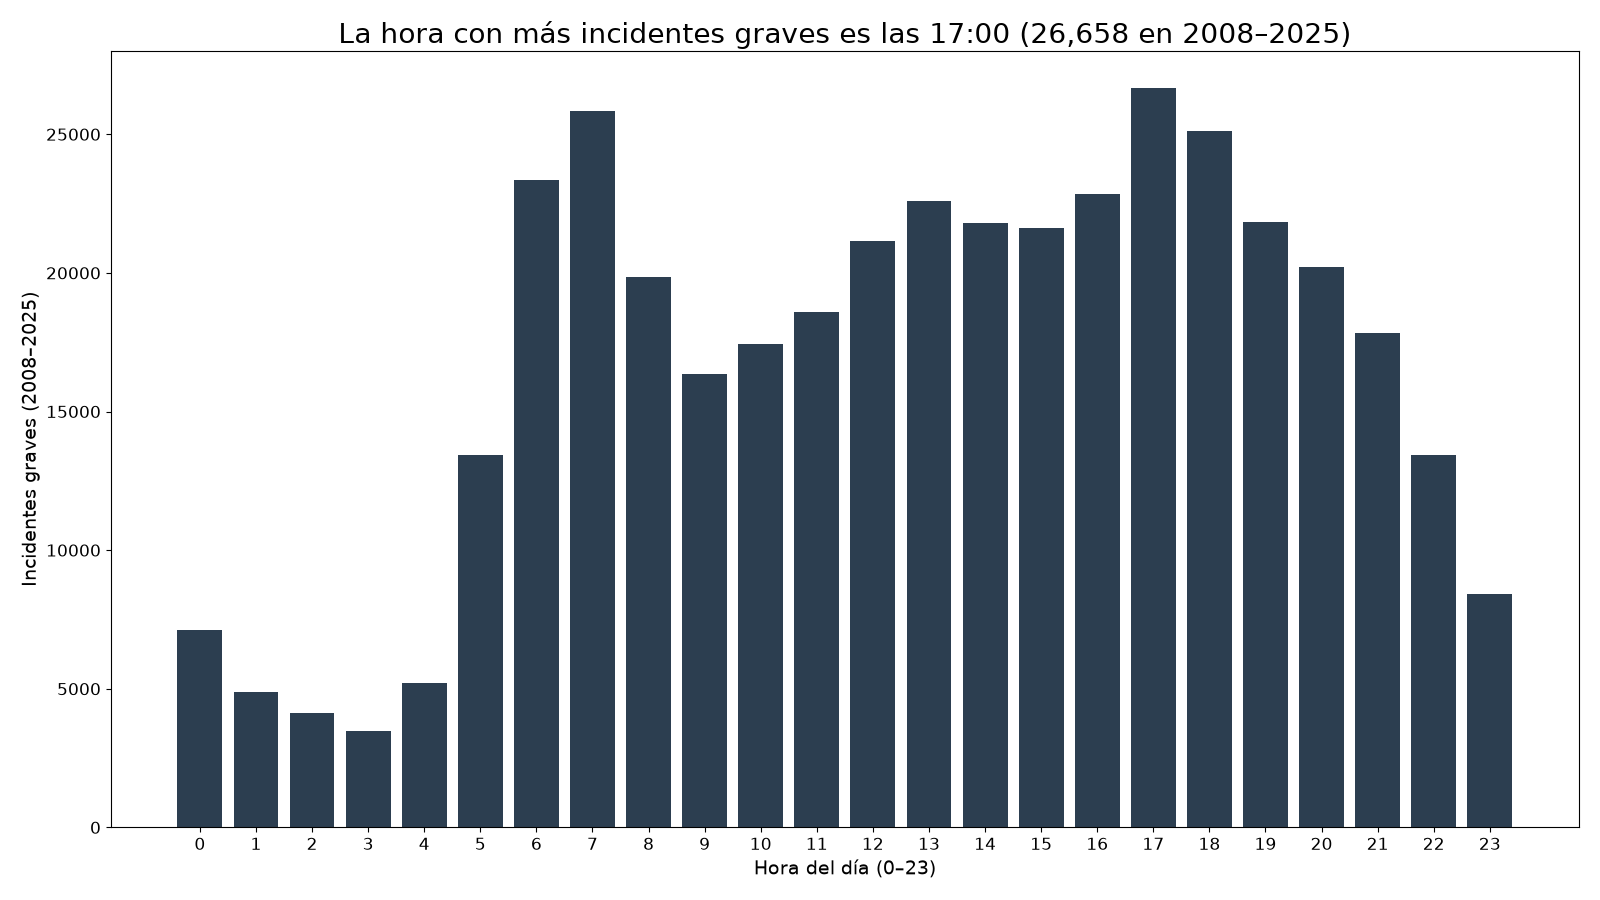

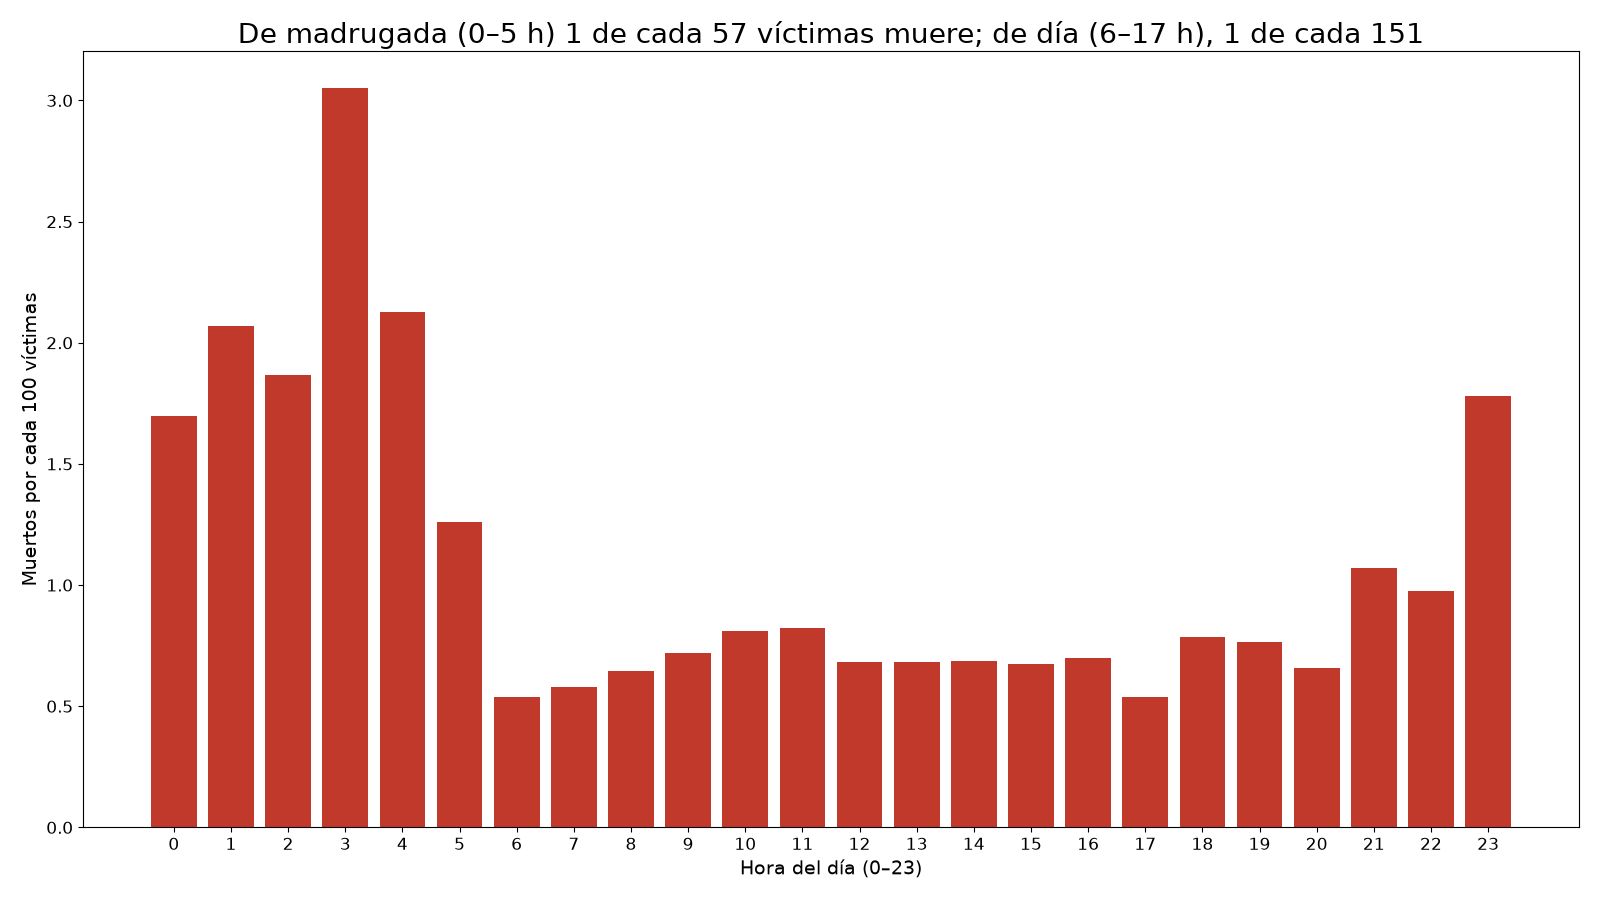

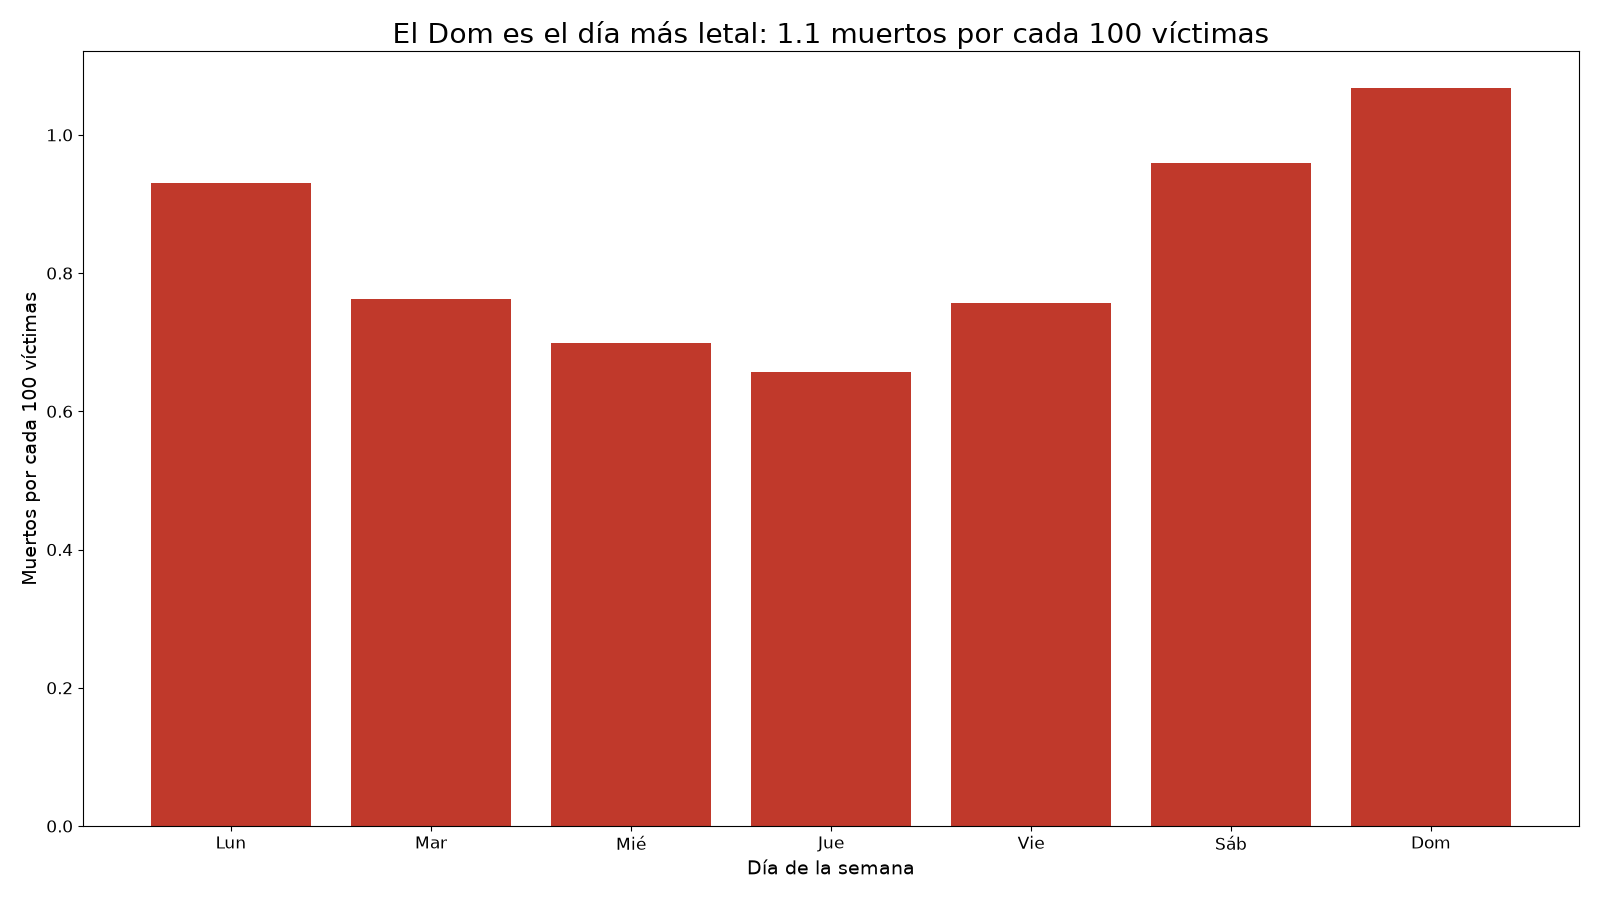

In [5]:
dg.fig_hora_incidentes(inc)
dg.fig_hora_letalidad(vic)
dg.fig_dia_semana(vic)
for f in ["02_incidentes_graves_por_hora", "03_letalidad_por_hora", "04_letalidad_por_dia"]:
    display(Image(f"figuras/{f}.png"))

## 4. Actor vial

                  victimas  muertos  letalidad_por_100
actor                                                 
Moto                178326      883               0.50
Peatón               32395      890               2.75
Carro y pasajero     19717       80               0.41
Ciclista              5405       96               1.78
figura guardada: 05_victimas_y_letalidad_por_actor.png


,actor,victimas,muertos,letalidad_por_100
0,Moto,178326,883,0.50
1,Peatón,32395,890,2.75
2,Carro y pasajero,19717,80,0.41
3,Ciclista,5405,96,1.78


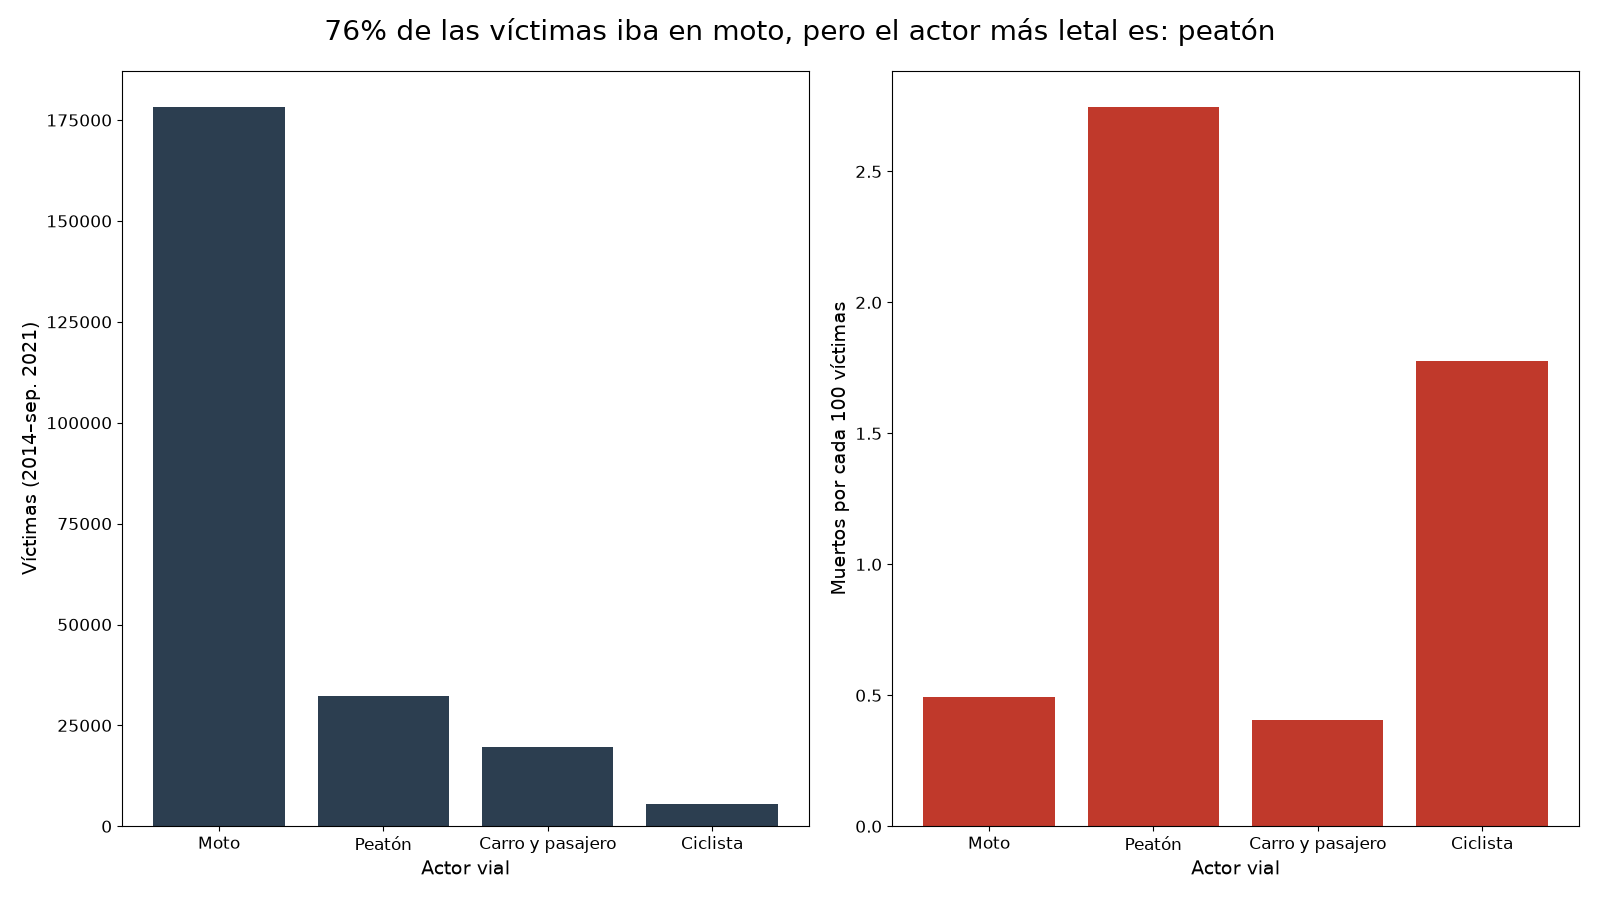

In [6]:
dg.fig_actor(vic)
display(pd.read_csv("data/processed/diag_actor.csv"))
display(Image("figuras/05_victimas_y_letalidad_por_actor.png"))

## 5. Mapa de muertos

Mapa: el 10 % de celdas con más muertes concentra 39% de 1537 fallecidos
figura guardada: 06_mapa_muertos_2019_2024.png


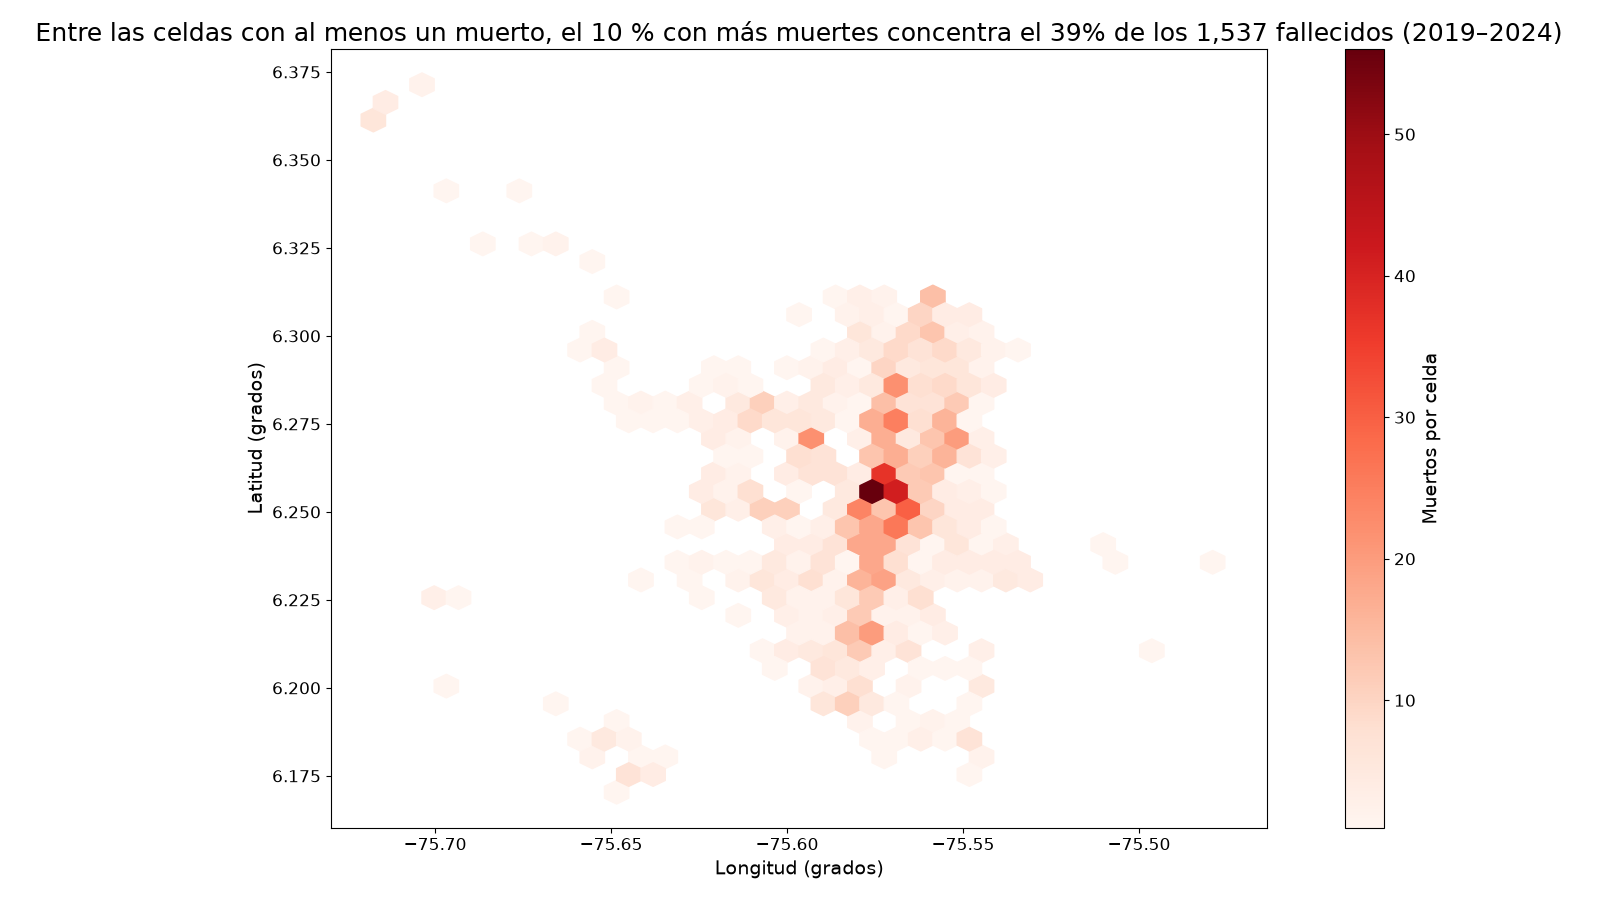

In [7]:
dg.fig_mapa(mor)
display(Image("figuras/06_mapa_muertos_2019_2024.png"))

## 6. Concentración por corredor (pendiente)
La frase "el X % de los corredores concentra el Y % de las muertes" requiere `catalogo_corredores.csv`
(Johan) y la asignación de corredor. Se completa cuando llegue.

## 7. Pruebas de aceptación

In [8]:
from src.fuentes import FUENTES

for clave in ["incidentes_itm", "victimas_medata", "motos_medata", "mortalidad_distrito"]:
    assert FUENTES[clave]["url"].startswith("http"), f"Falta la URL de {clave}"

inc_t = seg.incidentes_limpios()
cols = ["incidente_id","fuente","fecha","hora","anio","mes","dia_semana","gravedad","clase",
        "hay_moto","hay_peaton","lat","lon","direccion_normalizada","comuna","barrio",
        "corredor_id","metodo_asignacion"]
assert list(inc_t.columns) == cols
assert inc_t["incidente_id"].is_unique
assert inc_t["hora"].dropna().between(0, 23).all()
assert inc_t["dia_semana"].between(0, 6).all()
assert set(inc_t["gravedad"].unique()) <= {"solo_danos", "herido", "muerto"}
assert set(inc_t["metodo_asignacion"].unique()) <= {"coordenadas", "direccion", "sin_asignar"}
assert inc_t["hay_moto"].dropna().isin([0, 1]).all() and inc_t["hay_peaton"].dropna().isin([0, 1]).all()
assert (inc_t["lat"].isna() | inc_t["lat"].between(6.1, 6.4)).all()

ruta_cat = "data/processed/catalogo_corredores.csv"
if os.path.exists(ruta_cat):
    cat = pd.read_csv(ruta_cat)
    assert inc_t["corredor_id"].dropna().isin(cat["corredor_id"]).all()
    print("Contrato cumplido, incluido el catálogo de corredores")
else:
    print("Contrato cumplido (falta verificar corredor_id: todavía no hay catálogo)")

incidentes_limpios: 702540 leídas | eliminadas (sin fecha o sin gravedad): 0 | final: 702540 | sin coordenadas: 44785 | sin dirección: 15365
Contrato cumplido (falta verificar corredor_id: todavía no hay catálogo)


## Fuentes

In [9]:
for k in ["incidentes_itm", "victimas_medata", "motos_medata", "mortalidad_distrito"]:
    print("-", citar(k))

- Arango, Quiceno y Correa (2026). Dataset on Road Traffic Fatalities in Medellín, Colombia (2008–2025). Mendeley Data, DOI 10.17632/r6g5dfnpgh.1. https://data.mendeley.com/datasets/r6g5dfnpgh/1. Licencia: CC BY 4.0.
- MEData – Víctimas en Incidentes viales (Secretaría de Movilidad de Medellín). https://medata.app.medellin.gov.co/dataset/1-023-25-000360. Licencia: CC BY-SA 4.0.
- MEData – Incidentes Viales con Motos (Secretaría de Movilidad de Medellín). https://medata.app.medellin.gov.co/dataset/1-023-25-000277. Licencia: CC BY-SA 4.0.
- Alcaldía de Medellín – Secretaría de Movilidad – Observatorio de Movilidad, capa Mortalidad. https://www.medellin.gov.co/servidormapas/rest/services/transporte/VM_Mortalidad/MapServer/0. Licencia: Uso para análisis y planificación (ver metadatos de la capa).
